In [1]:
import numpy as np
import pandas as pd
from pandas import read_excel

df_cibil = pd.read_excel('data/External_Cibil_Dataset.xlsx' , engine='openpyxl')
df_bank = pd.read_excel('data/Internal_Bank_Dataset.xlsx', engine='openpyxl')
df_cibil.describe()

,PROSPECTID,time_since_recent_payment,time_since_first_deliquency,time_since_recent_deliquency,num_times_delinquent,max_delinquency_level,max_recent_level_of_deliq,num_deliq_6mts,num_deliq_12mts,num_deliq_6_12mts,...,PL_utilization,PL_Flag,pct_PL_enq_L6m_of_L12m,pct_CC_enq_L6m_of_L12m,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,max_unsec_exposure_inPct,HL_Flag,GL_Flag,Credit_Score
count,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,...,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000,51336.000000
mean,25668.500000,-8129.961314,-70020.091320,-70022.375838,1.573749,-70003.987085,13.521953,0.184977,0.480053,0.295076,...,-86556.225194,0.167874,0.190414,0.065182,0.170492,0.056302,-45127.943635,0.271116,0.052887,679.859222
std,14819.571046,27749.328514,45823.312757,45819.820741,4.165012,45847.976100,53.336976,0.710240,1.522210,1.027471,...,34111.414750,0.373758,0.376218,0.235706,0.350209,0.213506,49795.784556,0.444540,0.223810,20.502764
min,1.000000,-99999.000000,-99999.000000,-99999.000000,0.000000,-99999.000000,0.000000,0.000000,0.000000,0.000000,...,-99999.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-99999.000000,0.000000,0.000000,469.000000
25%,12834.750000,46.000000,-99999.000000,-99999.000000,0.000000,-99999.000000,0.000000,0.000000,0.000000,0.000000,...,-99999.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-99999.000000,0.000000,0.000000,669.000000
50%,25668.500000,70.000000,-99999.000000,-99999.000000,0.000000,-99999.000000,0.000000,0.000000,0.000000,0.000000,...,-99999.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.333000,0.000000,0.000000,680.000000
75%,38502.250000,161.000000,8.000000,3.000000,1.000000,15.000000,10.000000,0.000000,0.000000,0.000000,...,-99999.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.164250,1.000000,0.000000,691.000000
max,51336.000000,6065.000000,35.000000,35.000000,74.000000,900.000000,900.000000,12.000000,28.000000,20.000000,...,1.708000,1.000000,1.000000,1.000000,1.000000,1.000000,173800.000000,1.000000,1.000000,811.000000


### Merging the two datasets

In [2]:
# 2. Execute the Inner Join on the mutual primary key column
df_master = pd.merge(df_bank, df_cibil, on='PROSPECTID', how='inner')

# 3. Print out structural checkpoints to check the alignment
print(f"Internal Bank Dimensions:  {df_bank.shape}")
print(f"External CIBIL Dimensions: {df_cibil.shape}")
print(f"Merged Master Dimensions:   {df_master.shape}")


Internal Bank Dimensions:  (51336, 26)
External CIBIL Dimensions: (51336, 62)
Merged Master Dimensions:   (51336, 87)


In [3]:
df_master.head()

,PROSPECTID,Total_TL,Tot_Closed_TL,Tot_Active_TL,Total_TL_opened_L6M,Tot_TL_closed_L6M,pct_tl_open_L6M,pct_tl_closed_L6M,pct_active_tl,pct_closed_tl,...,pct_CC_enq_L6m_of_L12m,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,max_unsec_exposure_inPct,HL_Flag,GL_Flag,last_prod_enq2,first_prod_enq2,Credit_Score,Approved_Flag
0,1,5,4,1,0,0,0.000,0.0,0.200,0.800,...,0.0,0.0,0.0,13.333,1,0,PL,PL,696,P2
1,2,1,0,1,0,0,0.000,0.0,1.000,0.000,...,0.0,0.0,0.0,0.860,0,0,ConsumerLoan,ConsumerLoan,685,P2
2,3,8,0,8,1,0,0.125,0.0,1.000,0.000,...,0.0,0.0,0.0,5741.667,1,0,ConsumerLoan,others,693,P2
3,4,1,0,1,1,0,1.000,0.0,1.000,0.000,...,0.0,0.0,0.0,9.900,0,0,others,others,673,P2
4,5,3,2,1,0,0,0.000,0.0,0.333,0.667,...,0.0,0.0,0.0,-99999.000,0,0,AL,AL,753,P1


In [4]:
# Step 1: Create a flag for the good behavior BEFORE you clean the numbers
# If they have 0 delinquencies, we flag them as a '1' (True) in a new column
df_master['Clean_History_Flag'] = (df_master['num_times_delinquent'] == 0).astype(int)

# Step 2: Now that you have saved that structural information,
# you can safely convert all the -99999 sentinels to standard NaNs
df_master.replace(-99999, np.nan, inplace=True)
df_master.head()


,PROSPECTID,Total_TL,Tot_Closed_TL,Tot_Active_TL,Total_TL_opened_L6M,Tot_TL_closed_L6M,pct_tl_open_L6M,pct_tl_closed_L6M,pct_active_tl,pct_closed_tl,...,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,max_unsec_exposure_inPct,HL_Flag,GL_Flag,last_prod_enq2,first_prod_enq2,Credit_Score,Approved_Flag,Clean_History_Flag
0,1,5,4,1,0,0,0.000,0.0,0.200,0.800,...,0.0,0.0,13.333,1,0,PL,PL,696,P2,0
1,2,1,0,1,0,0,0.000,0.0,1.000,0.000,...,0.0,0.0,0.860,0,0,ConsumerLoan,ConsumerLoan,685,P2,1
2,3,8,0,8,1,0,0.125,0.0,1.000,0.000,...,0.0,0.0,5741.667,1,0,ConsumerLoan,others,693,P2,0
3,4,1,0,1,1,0,1.000,0.0,1.000,0.000,...,0.0,0.0,9.900,0,0,others,others,673,P2,1
4,5,3,2,1,0,0,0.000,0.0,0.333,0.667,...,0.0,0.0,NaN,0,0,AL,AL,753,P1,1


In [5]:
# 1. Calculate the percentage of missing values per column
missing_pct = (df_master.isnull().sum() / len(df_master)) * 100

# 2. Filter for columns with MORE THAN 25% missing data
cols_above_25 = missing_pct[missing_pct > 25].sort_values(ascending=False)

print(f"Number of columns with >25% missing values: {len(cols_above_25)}\n")
print("Columns and their Missing Percentages:")
print(cols_above_25)

Number of columns with >25% missing values: 7

Columns and their Missing Percentages:
CC_utilization                  92.792582
PL_utilization                  86.557192
time_since_first_deliquency     70.026882
max_delinquency_level           70.026882
time_since_recent_deliquency    70.026882
max_unsec_exposure_inPct        45.149603
max_deliq_6mts                  25.109085
dtype: float64


In [6]:
# 1. Drop the columns that are mostly empty noise
cols_to_drop = ['CC_utilization', 'PL_utilization', 'max_unsec_exposure_inPct']
df_master.drop(columns=cols_to_drop, inplace=True, errors='ignore')

# 2. Extract the critical business signal from the Delinquency features BEFORE handling NaNs
# 1 = Borrower has a delinquency history (High Risk), 0 = Borrower is completely clean (70% group)
df_master['Has_Delinquency_History'] = df_master['time_since_recent_deliquency'].notna().astype(int)

# 3. For the remaining delinquency columns, fill NaNs with 0
# (Now safe because Has_Delinquency_History tells the model who is actually clean vs defaulted)
delinquency_cols = ['time_since_first_deliquency', 'max_delinquency_level',
                    'time_since_recent_deliquency', 'max_deliq_6mts']

for col in delinquency_cols:
    if col in df_master.columns:
        df_master[col].fillna(0, inplace=True)

print(f"Cleanup complete! New DataFrame Shape: {df_master.shape}")

Cleanup complete! New DataFrame Shape: (51336, 86)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_12212\3660020354.py:16: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_master[col].fillna(0, inplace=True)


In [7]:
print([c for c in df_master.columns if any(k in c.lower() for k in ['util', 'cc', 'pl', 'foir', 'income', 'tot'])])

['Total_TL', 'Tot_Closed_TL', 'Tot_Active_TL', 'Total_TL_opened_L6M', 'Tot_TL_closed_L6M', 'Total_TL_opened_L12M', 'Tot_TL_closed_L12M', 'Tot_Missed_Pmnt', 'CC_TL', 'PL_TL', 'tot_enq', 'CC_enq', 'CC_enq_L6m', 'CC_enq_L12m', 'PL_enq', 'PL_enq_L6m', 'PL_enq_L12m', 'NETMONTHLYINCOME', 'CC_Flag', 'PL_Flag', 'pct_PL_enq_L6m_of_L12m', 'pct_CC_enq_L6m_of_L12m', 'pct_PL_enq_L6m_of_ever', 'pct_CC_enq_L6m_of_ever']


In [8]:
import numpy as np
import pandas as pd

# 1. Clean whitespace from column headers
df_master.columns = df_master.columns.str.strip()

# 2. Engineer FOIR (Unsecured Account Ratio) & Delinquency Rate
df_master['FOIR'] = (df_master['CC_TL'] + df_master['PL_TL']) / (
    df_master['Total_TL'] + 1
)
df_master['Missed_Pmnt_Rate'] = df_master['Tot_Missed_Pmnt'] / (
    df_master['Total_TL'] + 1
)

# 3. Short diagnostic output
print(
    'Nulls:', df_master[['FOIR', 'Missed_Pmnt_Rate']].isnull().sum().to_dict()
)
print(
    df_master[['NETMONTHLYINCOME', 'FOIR', 'Missed_Pmnt_Rate']]
    .describe()
    .round(2)
    .loc[['count', 'mean', 'max']]
)

Nulls: {'FOIR': 0, 'Missed_Pmnt_Rate': 0}
       NETMONTHLYINCOME      FOIR  Missed_Pmnt_Rate
count          51336.00  51336.00          51336.00
mean           26424.19      0.07              0.09
max          2500000.00      0.93              0.83


In [9]:
# 1. Get all string/text column names
categorical_cols = df_master.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Total Categorical Columns: {len(categorical_cols)}\n")

# 2. Inspect unique values for each categorical column
for col in categorical_cols:
    unique_vals = df_master[col].unique()
    print(f"Column: '{col}' | Unique Count: {len(unique_vals)}")
    print(f"Values: {unique_vals}\n")

Total Categorical Columns: 6

Column: 'MARITALSTATUS' | Unique Count: 2
Values: <StringArray>
['Married', 'Single']
Length: 2, dtype: str

Column: 'EDUCATION' | Unique Count: 7
Values: <StringArray>
[          '12TH',       'GRADUATE',            'SSC',  'POST-GRADUATE',
 'UNDER GRADUATE',         'OTHERS',   'PROFESSIONAL']
Length: 7, dtype: str

Column: 'GENDER' | Unique Count: 2
Values: <StringArray>
['M', 'F']
Length: 2, dtype: str

Column: 'last_prod_enq2' | Unique Count: 6
Values: <StringArray>
['PL', 'ConsumerLoan', 'others', 'AL', 'CC', 'HL']
Length: 6, dtype: str

Column: 'first_prod_enq2' | Unique Count: 6
Values: <StringArray>
['PL', 'ConsumerLoan', 'others', 'AL', 'HL', 'CC']
Length: 6, dtype: str

Column: 'Approved_Flag' | Unique Count: 4
Values: <StringArray>
['P2', 'P1', 'P3', 'P4']
Length: 4, dtype: str



C:\Users\ASUS\AppData\Local\Temp\ipykernel_12212\492844099.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_master.select_dtypes(include=['object', 'category']).columns.tolist()


In [10]:


# 1. Isolate target variable y and drop primary key
X = df_master.drop(columns=['PROSPECTID', 'Approved_Flag'], errors='ignore')
y = df_master['Approved_Flag'].map({'P1': 0, 'P2': 1, 'P3': 2, 'P4': 3})

# 2. Ordinal Mapping for EDUCATION (Hierarchical)
edu_map = {
    'SSC': 0,
    'OTHERS': 0,
    '12TH': 1,
    'UNDER GRADUATE': 1,
    'GRADUATE': 2,
    'POST-GRADUATE': 3
}
if 'EDUCATION' in X.columns:
    X['EDUCATION'] = X['EDUCATION'].map(edu_map).fillna(0)

# 3. One-Hot Encoding for Low-Cardinality Nominal Columns
nominal_cols = ['MARITALSTATUS', 'GENDER', 'last_prod_enq2', 'first_prod_enq2']
X = pd.get_dummies(X, columns=[col for col in nominal_cols if col in X.columns], drop_first=True, dtype=int)

print("Encoding Completed Successfully!")
print(f"Processed Feature Matrix Shape (X): {X.shape}")
print(f"Target Vector Shape (y): {y.shape}")

Encoding Completed Successfully!
Processed Feature Matrix Shape (X): (51336, 94)
Target Vector Shape (y): (51336,)


In [11]:
from sklearn.model_selection import train_test_split

# 1. First Split: 70% Train, 30% Temp (Val + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 2. Second Split: Split the 30% Temp evenly into 15% Val and 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train Set Shape : {X_train.shape} ({len(X_train)/len(X)*100:.0f}%)")
print(f"Val Set Shape   : {X_val.shape} ({len(X_val)/len(X)*100:.0f}%)")
print(f"Test Set Shape  : {X_test.shape} ({len(X_test)/len(X)*100:.0f}%)")

Train Set Shape : (35935, 94) (70%)
Val Set Shape   : (7700, 94) (15%)
Test Set Shape  : (7701, 94) (15%)


In [12]:
from sklearn.preprocessing import StandardScaler

# Instantiate Scaler
scaler = StandardScaler()

# FIT + TRANSFORM exclusively on X_train to prevent leakage
X_train_scaled = scaler.fit_transform(X_train)

# TRANSFORM Validation and Test sets using parameters learned from X_train
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete! Train matrix ready for Isolation Forest.")

Scaling complete! Train matrix ready for Isolation Forest.


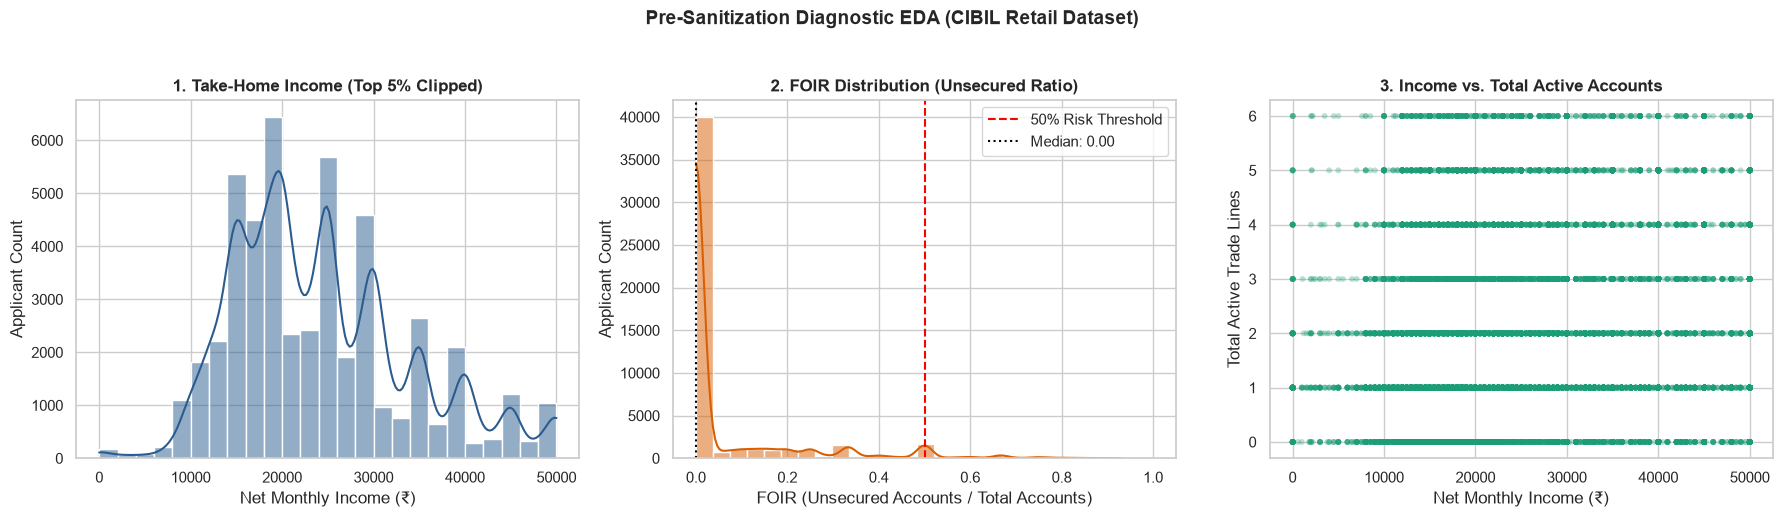

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.options.mode.chained_assignment = None
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))


# GRAPH 1: Take-Home Income (Top 5% Extreme Earners Clipped)

inc_vals = pd.to_numeric(
    df_master['NETMONTHLYINCOME'], errors='coerce'
).dropna()
p95_inc = inc_vals.quantile(0.95)
inc_plot = inc_vals[(inc_vals > 0) & (inc_vals <= p95_inc)]

sns.histplot(inc_plot, kde=True, ax=axes[0], color='#2b5c8f', bins=25)
axes[0].set_title(
    '1. Take-Home Income (Top 5% Clipped)',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel('Net Monthly Income (₹)')
axes[0].set_ylabel('Applicant Count')

# GRAPH 2: FOIR Ratio (Unsecured Loan Ratio: 0.0 to 1.0)

foir_vals = pd.to_numeric(df_master['FOIR'], errors='coerce').dropna()

sns.histplot(foir_vals, kde=True, ax=axes[1], color='#d95f02', bins=25)
axes[1].axvline(
    x=0.50,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='50% Risk Threshold',
)
axes[1].axvline(
    x=foir_vals.median(),
    color='black',
    linestyle=':',
    linewidth=1.5,
    label=f'Median: {foir_vals.median():.2f}',
)
axes[1].set_title(
    '2. FOIR Distribution (Unsecured Ratio)', fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('FOIR (Unsecured Accounts / Total Accounts)')
axes[1].set_ylabel('Applicant Count')
axes[1].set_xlim(-0.05, 1.05)
axes[1].legend(loc='upper right')

# GRAPH 3: Monthly Income vs. Active Accounts

tl_vals = pd.to_numeric(df_master['Tot_Active_TL'], errors='coerce')
p95_tl = tl_vals.quantile(0.95)

scatter_df = df_master[
    (inc_vals > 0)
    & (inc_vals <= p95_inc)
    & (tl_vals >= 0)
    & (tl_vals <= p95_tl)
]

axes[2].scatter(
    scatter_df['NETMONTHLYINCOME'],
    scatter_df['Tot_Active_TL'],
    alpha=0.30,
    color='#1b9e77',
    edgecolors='none',
    s=18,
)
axes[2].set_title(
    '3. Income vs. Total Active Accounts', fontsize=12, fontweight='bold'
)
axes[2].set_xlabel('Net Monthly Income (₹)')
axes[2].set_ylabel('Total Active Trade Lines')

plt.suptitle(
    'Pre-Sanitization Diagnostic EDA (CIBIL Retail Dataset)',
    fontsize=14,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()
plt.show()

In [14]:
import numpy as np
import pandas as pd

# Check unique values and class counts in y_test
print("Unique values in y_test:", np.unique(y_test))
print("Number of unique classes:", len(np.unique(y_test)))

Unique values in y_test: [0 1 2 3]
Number of unique classes: 4


In [15]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

# 1. BINARIZE TARGET (Handles string 'P3'/'P4' or integer 2/3)
high_risk_classes = ["P3", "P4", 2, 3, "2", "3"]
y_train_binary = y_train.isin(high_risk_classes).astype(int)
y_test_binary = y_test.isin(high_risk_classes).astype(int)

# 2. SELECT NUMERIC COLUMNS ONLY (Prevents string/text ValueError in SimpleImputer)
# Also drop ID columns or Credit_Score if you want a pure behavioral model
cols_to_drop = ["PROSPECTID", "Credit_Score", "Approved_Flag"]
X_train_num = X_train.select_dtypes(include=[np.number]).drop(
    columns=cols_to_drop, errors="ignore"
)
X_test_num = X_test.select_dtypes(include=[np.number]).drop(
    columns=cols_to_drop, errors="ignore"
)

# Save the exact numeric column names so lengths always match 100%
numeric_feature_names = X_train_num.columns.tolist()

# 3. IMPUTE MISSING VALUES & SCALE
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train_num)
X_test_imp = imputer.transform(X_test_num)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

# 4. TRAIN BASELINE LOGISTIC REGRESSION
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_scaled, y_train_binary)

# 5. PREDICT & EVALUATE
y_pred_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]
y_pred = baseline_model.predict(X_test_scaled)

auc_score = roc_auc_score(y_test_binary, y_pred_proba)
gini_score = (2 * auc_score) - 1
recall = recall_score(y_test_binary, y_pred, average="macro")

print(" BASELINE MODEL PERFORMANCE")
print(f"ROC-AUC Score : {auc_score:.4f}")
print(f"Gini Score    : {gini_score:.4f}")
print(f"Recall        : {recall:.4f}\n")

# 6. SAFE FEATURE IMPORTANCE AUDIT (Guaranteed matching lengths)
leakage_audit = pd.DataFrame(
    {
        "Feature": numeric_feature_names,
        "Coefficient_Weight": baseline_model.coef_[0],
    }
)
leakage_audit["Absolute_Impact"] = leakage_audit["Coefficient_Weight"].abs()
leakage_audit = leakage_audit.sort_values(
    by="Absolute_Impact", ascending=False
)

print("--- TOP 5 MOST INFLUENTIAL FEATURES ---")
print(leakage_audit.head(5).to_string(index=False))

--- BASELINE MODEL PERFORMANCE ---
ROC-AUC Score : 0.9287
Gini Score    : 0.8574
Recall        : 0.8392

--- TOP 5 MOST INFLUENTIAL FEATURES ---
                     Feature  Coefficient_Weight  Absolute_Impact
                     enq_L3m            2.269975         2.269975
               Age_Oldest_TL           -1.707238         1.707238
time_since_recent_deliquency            0.930723         0.930723
             max_deliq_12mts            0.899232         0.899232
               num_std_12mts           -0.850666         0.850666


In [16]:
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

# 1. Initialize and fit Isolation Forest on scaled training features
iso_forest = IsolationForest(
    contamination=0.01,  # Target top 1% extreme anomalies
    random_state=42,
    n_jobs=-1
)

# 2. Predict anomaly flags (-1 = Anomaly/Outlier, 1 = Normal/Inlier)
outlier_flags = iso_forest.fit_predict(X_train_scaled)

# 3. Create boolean mask for clean rows
clean_mask = (outlier_flags == 1)

# 4. Synchronize and filter X_train, X_train_scaled, and y_train
X_train_clean = X_train[clean_mask].copy()
X_train_scaled_clean = X_train_scaled[clean_mask].copy()
y_train_clean = y_train[clean_mask].copy()

print(f"Original Training Rows: {len(X_train)}")
print(f"Anomalies Removed: {np.sum(outlier_flags == -1)}")
print(f"Sanitized Training Rows: {len(X_train_clean)}")

Original Training Rows: 35935
Anomalies Removed: 360
Sanitized Training Rows: 35575


In [17]:
import pandas as pd

# 1. Separate original (unscaled) training data into Normal vs. Anomaly
clean_df = X_train[outlier_flags == 1]
anomalies_df = X_train[outlier_flags == -1]

# 2. Build a comparative summary table
comparison_table = pd.DataFrame({
    "Normal Borrowers (Mean)": clean_df.mean(),
    "Removed Anomalies (Mean)": anomalies_df.mean(),
    "Absolute Difference": anomalies_df.mean() - clean_df.mean(),
    "Percentage Shift (%)": ((anomalies_df.mean() - clean_df.mean()) / clean_df.mean()) * 100
})

print(f"Total Profiles Evaluated: {len(X_train)}")
print(f"Normal Inliers Retained:  {len(clean_df)} ({len(clean_df)/len(X_train):.1%})")
print(f"Anomalies Isolated:       {len(anomalies_df)} ({len(anomalies_df)/len(X_train):.1%})\n")

print("=== Feature Profile Comparison: Normal vs. Removed Anomalies ===")
display(comparison_table.round(2))

Total Profiles Evaluated: 35935
Normal Inliers Retained:  35575 (99.0%)
Anomalies Isolated:       360 (1.0%)

=== Feature Profile Comparison: Normal vs. Removed Anomalies ===


,Normal Borrowers (Mean),Removed Anomalies (Mean),Absolute Difference,Percentage Shift (%)
Total_TL,4.59,27.08,22.49,489.82
Tot_Closed_TL,2.59,18.24,15.65,604.87
Tot_Active_TL,2.00,8.84,6.84,341.25
Total_TL_opened_L6M,0.70,4.20,3.50,503.71
Tot_TL_closed_L6M,0.40,2.59,2.19,542.69
...,...,...,...,...
first_prod_enq2_CC,0.04,0.18,0.13,317.27
first_prod_enq2_ConsumerLoan,0.23,0.20,-0.03,-11.94
first_prod_enq2_HL,0.03,0.05,0.02,74.63
first_prod_enq2_PL,0.09,0.18,0.08,89.81


In [18]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# 1. Overriding the Silhouette mathematical peak to align with Business Persona requirements
optimal_k = 4
print(f"Overriding mathematical peak. Forcing Business Optimal Personas (K): {optimal_k}")

# 2. Fitting final KMeans model using K=4
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
persona_labels = final_kmeans.fit_predict(X_train_scaled_clean)

# 3. Attaching Persona Cluster IDs back to clean training DataFrames
X_train_clean_labeled = X_train_clean.copy()
X_train_clean_labeled["Persona_Cluster"] = persona_labels

# 4. Generating the Borrower Persona Profile Summary Table
persona_summary = X_train_clean_labeled.groupby("Persona_Cluster").mean()
cluster_counts = X_train_clean_labeled["Persona_Cluster"].value_counts().sort_index()
cluster_shares = (cluster_counts / len(X_train_clean_labeled)) * 100

profile_table = pd.DataFrame({
    "Borrower Count": cluster_counts,
    "Population Share (%)": cluster_shares.round(1)
}).join(persona_summary.round(2))

print("\nBusiness-Optimized Borrower Persona Profile Summary ")
display(profile_table)

Overriding mathematical peak. Forcing Business Optimal Personas (K): 4

Business-Optimized Borrower Persona Profile Summary 


,Borrower Count,Population Share (%),Total_TL,Tot_Closed_TL,Tot_Active_TL,Total_TL_opened_L6M,Tot_TL_closed_L6M,pct_tl_open_L6M,pct_tl_closed_L6M,pct_active_tl,...,last_prod_enq2_CC,last_prod_enq2_ConsumerLoan,last_prod_enq2_HL,last_prod_enq2_PL,last_prod_enq2_others,first_prod_enq2_CC,first_prod_enq2_ConsumerLoan,first_prod_enq2_HL,first_prod_enq2_PL,first_prod_enq2_others
Persona_Cluster,,,,,,,,,,,,,,,,,,,,,
0,4108,11.5,7.92,3.67,4.25,2.15,1.19,0.35,0.14,0.63,...,0.21,0.39,0.00,0.26,0.12,0.16,0.31,0.02,0.13,0.33
1,3873,10.9,13.42,9.58,3.84,0.98,0.80,0.08,0.07,0.39,...,0.03,0.35,0.03,0.15,0.39,0.04,0.15,0.06,0.12,0.52
2,15614,43.9,2.26,0.40,1.86,0.66,0.12,0.28,0.03,0.90,...,0.02,0.36,0.02,0.15,0.42,0.03,0.22,0.03,0.10,0.58
3,11980,33.7,3.64,2.81,0.83,0.15,0.38,0.03,0.15,0.20,...,0.02,0.31,0.02,0.12,0.50,0.02,0.24,0.02,0.06,0.60


In [19]:
import xgboost as xgb

# 1. Converting engineered Persona ID into a pure category (not a continuous number)
X_train_clean_labeled['Persona_Cluster'] = X_train_clean_labeled['Persona_Cluster'].astype('category')

# 2. Calculating the exact class imbalance ratio dynamically
negative_class_count = (y_train_clean == 0).sum()
positive_class_count = (y_train_clean == 1).sum()
imbalance_ratio = negative_class_count / positive_class_count

print(f"Good Borrowers (0): {negative_class_count}")
print(f"Defaulters (1):     {positive_class_count}")
print(f"Calculated scale_pos_weight: {imbalance_ratio:.2f}\n")

# 3. Initialize the XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=200,            # Number of decision trees
    learning_rate=0.05,          # How fast the model learns
    max_depth=5,                 # Limits tree depth to prevent overfitting
    scale_pos_weight=imbalance_ratio,  # Forces severe penalty for missing defaulters
    enable_categorical=True,     # Native support for Persona_Cluster feature
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

# 4. Train the Supervised Decision Engine
print("Training XGBoost Classifier")
xgb_model.fit(X_train_clean_labeled, y_train_clean)
print("Training Complete!")

Good Borrowers (0): 3987
Defaulters (1):     22459
Calculated scale_pos_weight: 0.18

Training XGBoost Classifier


C:\Users\ASUS\miniconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:15:58] WARNING: C:\Users\task_WRAU1tNeTHq2d_3\croot\xgboost-split_1783530578600\work\src\learner.cc:793: 
Parameters: { "scale_pos_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Training Complete!


1. Imputing and Re-Scaling the dataset...
2. Re-running Isolation Forest Sanitization...
3. Re-generating K-Means Personas (K=4)...
3.5 Binarizing Target Variable (P1/P2 -> 0, P3/P4 -> 1)...
4. Re-training XGBoost Classifier...
5. Evaluating Test Set...

=== Clean Pipeline Final Metrics ===
ROC-AUC Score:      0.9999
Gini Coefficient:   0.9998

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      5701
           1       0.98      1.00      0.99      2000

    accuracy                           1.00      7701
   macro avg       0.99      1.00      0.99      7701
weighted avg       1.00      1.00      1.00      7701



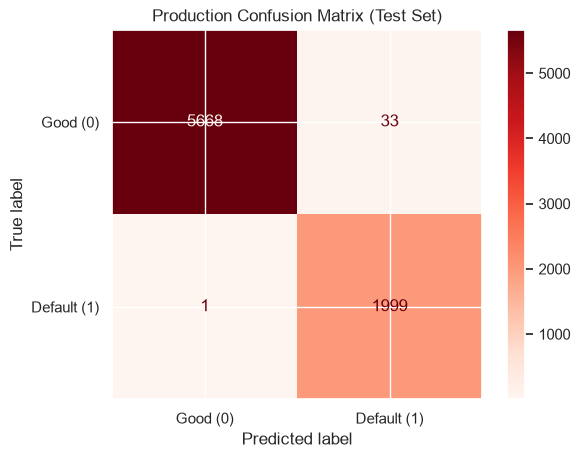

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
import xgboost as xgb
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

try:
    # 0. FAIL-SAFE MEMORY SWEEP
    if "Persona_Cluster" in X_train.columns:
        X_train = X_train.drop(columns=["Persona_Cluster"])
    if "Persona_Cluster" in X_test.columns:
        X_test = X_test.drop(columns=["Persona_Cluster"])

    print("1. Imputing and Re-Scaling the dataset...")
    imputer = SimpleImputer(strategy='median')
    X_train_imputed = imputer.fit_transform(X_train)
    X_test_imputed = imputer.transform(X_test)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_imputed)
    X_test_scaled = scaler.transform(X_test_imputed)

    print("2. Re-running Isolation Forest Sanitization...")
    iso_forest = IsolationForest(contamination=0.01, random_state=42, n_jobs=-1)
    clean_mask = (iso_forest.fit_predict(X_train_scaled) == 1)

    X_train_clean = X_train[clean_mask].copy()
    X_train_scaled_clean = X_train_scaled[clean_mask]
    y_train_clean = y_train[clean_mask].copy()

    print("3. Re-generating K-Means Personas (K=4)...")
    final_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

    X_train_scaled_clean = np.ascontiguousarray(X_train_scaled_clean)
    train_clusters = final_kmeans.fit_predict(X_train_scaled_clean)

    X_train_clean = X_train_clean.assign(Persona_Cluster=train_clusters)
    X_train_clean["Persona_Cluster"] = X_train_clean["Persona_Cluster"].astype('category')

    print("3.5 Binarizing Target Variable (P1/P2 -> 0, P3/P4 -> 1)...")
    # Collapse 4 classes into binary 0 (Good) and 1 (Default)
    y_train_binary = y_train_clean.replace({0: 0, 1: 0, 2: 1, 3: 1, 'P1': 0, 'P2': 0, 'P3': 1, 'P4': 1}).astype(int)
    y_test_binary = y_test.replace({0: 0, 1: 0, 2: 1, 3: 1, 'P1': 0, 'P2': 0, 'P3': 1, 'P4': 1}).astype(int)

    print("4. Re-training XGBoost Classifier...")
    imbalance_ratio = (y_train_binary == 0).sum() / (y_train_binary == 1).sum()
    xgb_model = xgb.XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=5,
        scale_pos_weight=imbalance_ratio, enable_categorical=True,
        tree_method='hist', random_state=42, n_jobs=-1
    )
    xgb_model.fit(X_train_clean, y_train_binary)

    print("5. Evaluating Test Set...\n")
    X_test_final = X_test.copy()

    X_test_scaled = np.ascontiguousarray(X_test_scaled)
    test_clusters = final_kmeans.predict(X_test_scaled)

    X_test_final = X_test_final.assign(Persona_Cluster=test_clusters)
    X_test_final["Persona_Cluster"] = X_test_final["Persona_Cluster"].astype('category')

    y_pred = xgb_model.predict(X_test_final)
    y_pred_proba = xgb_model.predict_proba(X_test_final)[:, 1]
    roc_auc = roc_auc_score(y_test_binary, y_pred_proba)

    print("="*40)
    print(f"=== Clean Pipeline Final Metrics ===")
    print("="*40)
    print(f"ROC-AUC Score:      {roc_auc:.4f}")
    print(f"Gini Coefficient:   {(2 * roc_auc) - 1:.4f}\n")
    print(classification_report(y_test_binary, y_pred))

    disp = ConfusionMatrixDisplay(confusion_matrix(y_test_binary, y_pred), display_labels=["Good (0)", "Default (1)"])
    disp.plot(cmap='Reds', values_format='d')
    plt.title("Production Confusion Matrix (Test Set)")
    plt.show()

except Exception as e:
    print("\n" + "!"*40)
    print("PIPELINE CRASHED!")
    print("!"*40)
    print(f"Error Type: {type(e).__name__}")
    print(f"Error Message: {str(e)}\n")

In [21]:
import joblib

print("Serializing pipeline components to disk...")

# 1. Save the Imputer (To handle missing values in new applications)
joblib.dump(imputer, 'imputer.pkl')

# 2. Save the Scaler (To scale new numbers using the exact same math)
joblib.dump(scaler, 'scaler.pkl')

# 3. Save the K-Means Model (To assign a behavioral persona)
joblib.dump(final_kmeans, 'kmeans_persona_model.pkl')

# 4. Save the XGBoost Model (To make the final Default prediction)
joblib.dump(xgb_model, 'xgboost_risk_model.pkl')

print("--> All models successfully saved!.")

Serializing pipeline components to disk...
--> All models successfully saved! You are officially done with the Notebook.
